# 02 - Different Plot Types
*Codecademy: Analyze Financial Data with Python / Visualizing Finance Data*

In [01_matplotlib_basics](01_matplotlib_basics.ipynb) everything was a line plot. In this lesson we learn other plot types - and when to use which one:

| plot type | what it's for | finance example |
|---|---|---|
| bar graph | comparing categories | revenue per business unit, returns per asset class |
| error bars / shading | showing uncertainty | a forecast with a confidence band, mean return ± standard deviation |
| pie chart | parts of a whole | portfolio allocation - 60% stocks, 30% bonds, 10% cash |
| histogram | how values are distributed | daily returns - how often a ±2% day happens |

Every chart is saved to `charts/` and collected in this folder's [README](README.md).

In [1]:
from matplotlib import pyplot as plt

CHARTS = 'charts/'

## 1. Simple Bar Chart
**Task:** the cafe MatplotSip sold six drinks last month - plot the sales as bars, with x-values `0, 1, ... n-1`.

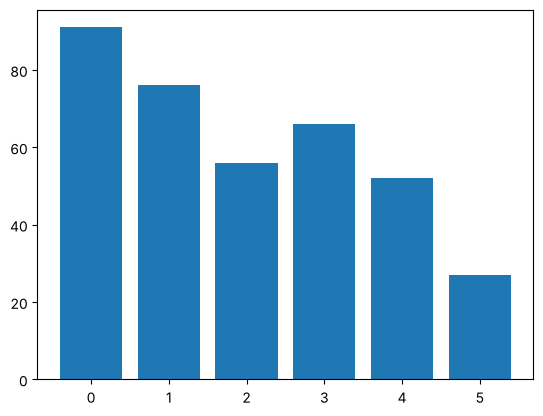

In [2]:
drinks = ["cappuccino", "latte", "chai", "americano", "mocha", "espresso"]
sales =  [91, 76, 56, 66, 52, 27]

plt.figure()
plt.bar(range(len(drinks)), sales)
plt.savefig(CHARTS + '02_01_simple_bar.png')
plt.show()

`plt.bar()` works like `plt.plot()`: x first, then y. The x-values are only **slots** for the categories:

```text
plt.bar(range(len(sales)), sales)
        \_______________/  \___/
         x: 0, 1, 2 ...     y: bar heights
         one slot per drink
```

We can't tell which bar is which drink yet - that's the next step.

**Finance tip:** a bar chart's y-axis should **always start at 0**. A bar's height *is* its value, so a cut-off axis makes small differences look huge (the truncated-axis warning from section 5 of the basics - even stricter for bars). Matplotlib starts bars at 0 by default.

## 2. Simple Bar Chart II - labels
**Task:** create the axes object `ax`, set the x-ticks to `0 ... len(drinks)`, and use the `drinks` list as tick labels.

range(0, 6)
[0, 1, 2, 3, 4, 5]


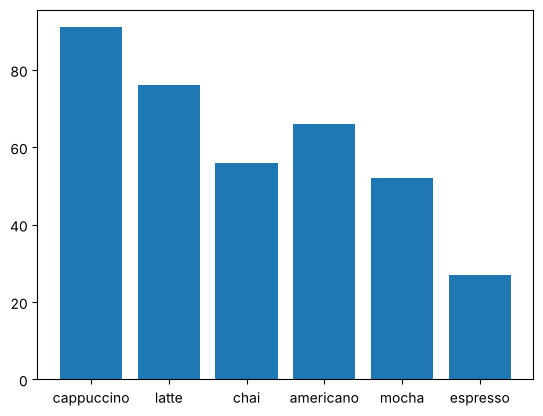

In [3]:
x = range(len(drinks))
print(x)          # what is this?
print(list(x))

plt.figure()
ax = plt.subplot()
plt.bar(x, sales)
ax.set_xticks(x)
ax.set_xticklabels(drinks)
plt.savefig(CHARTS + '02_02_bar_labels.png')
plt.show()

**Learning point:** `print(range(...))` shows `range(0, 6)`, not the numbers. `range` doesn't store the numbers - it's a recipe that hands them out one at a time when something asks. Matplotlib asks, so `set_xticks(range(...))` works; to *see* them, wrap it in `list()`. (In R, `0:5` gives the numbers directly - that's why this one is surprising.)

- Define `x` once and reuse it - no need to type `range(len(drinks))` three times.
- **Ticks before labels:** without explicit ticks, matplotlib might not put one tick under every bar, and the labels end up on the wrong bars.
- Long labels? `ax.set_xticklabels(drinks, rotation=30)` tilts them - useful for tickers or fund names.

## 3. Side-By-Side Bars
**Task:** MatplotSip opened a second location - plot the sales of both stores next to each other, using the x-value template below for each store.

store1_x: [0.8, 2.8, 4.8, 6.8, 8.8, 10.8]
store2_x: [1.6, 3.6, 5.6, 7.6, 9.6, 11.6]


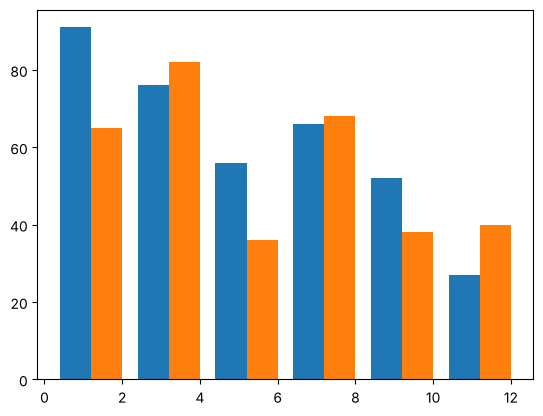

In [4]:
sales1 = [91, 76, 56, 66, 52, 27]
sales2 = [65, 82, 36, 68, 38, 40]

n = 1    # This is our first dataset (out of 2)
t = 2    # Number of datasets
d = 6    # Number of sets of bars
w = 0.8  # Width of each bar
store1_x = [t*element + w*n for element
             in range(d)]

n = 2    # This is our second dataset (out of 2)
t = 2    # Number of datasets
d = 6    # Number of sets of bars
w = 0.8  # Width of each bar
store2_x = [t*element + w*n for element
             in range(d)]

print('store1_x:', store1_x)
print('store2_x:', store2_x)

plt.figure()
plt.bar(store1_x, sales1)
plt.bar(store2_x, sales2)
plt.savefig(CHARTS + '02_03_side_by_side.png')
plt.show()

### The copy-paste template

```python
n = 1    # which dataset is this?      1st -> 1, 2nd -> 2, 3rd -> 3 ...
t = 2    # how many datasets in total  (bars per group)
d = 6    # how many groups             = len(categories), here len(drinks)
w = 0.8  # width of one bar            0.8 is matplotlib's default
store1_x = [t*element + w*n for element in range(d)]
```

**How to fill it in - 4 questions:**

| variable | ask yourself | MatplotSip |
|---|---|---|
| `n` | which dataset am I placing *right now*? | store 1 -> `1`, store 2 -> `2` |
| `t` | how many datasets sit next to each other? | 2 stores -> `2` |
| `d` | how many groups (categories) are on the x-axis? | 6 drinks -> `6` |
| `w` | how wide is one bar? | keep `0.8` |

**Rule:** paste the block once per dataset. Only `n` changes - `t`, `d`, `w` stay the same. Rename the result each time (`store1_x`, `store2_x`). Three datasets? Same block three times with `t = 3` and `n = 1, 2, 3`.

### What it does: it only picks the positions
The list only calculates **where** each bar stands on the x-axis. It doesn't draw anything and has nothing to do with the sales numbers:

```text
plt.bar(  store1_x,   sales1 )
          \______/    \____/
          where the   how tall
          bars stand  they are
```

It makes sure each comparison pair stands next to each other, **touching**, with a small **gap** before the next pair:

```text
 0.8  1.6        2.8  3.6        4.8  5.6
 [S1][S2]  gap   [S1][S2]  gap   [S1][S2]   ...
 cappuccino       latte            chai

touching: store 2 starts exactly 1 bar width (w = 0.8) after store 1
gap:      each group gets t = 2 units of space, the pair fills only 2 x 0.8 = 1.6
          -> 0.4 left empty before the next pair
```

### How the line works: `[t*element + w*n for element in range(d)]`

**Read it as a sentence, from the middle outwards:**
```text
[ t*element + w*n    for element in range(d) ]
  \_____________/    \____________________/
   2) calculate       1) for every number
      this ...           0, 1, 2, 3, 4, 5
```
"**For every** `element` in 0-5, **calculate** `t*element + w*n`, and **collect the results in a list**." The square brackets are the list being filled; `element` is just a name for "the number we're on right now".

**The formula:**
```text
t*element  +  w*n
\_______/     \_/
 jump to       move into this dataset's slot inside the group
 the group     (n=1: 1 bar width in, n=2: 2 bar widths in)
 (t units per group = room for t bars)
```

**The same thing as a normal loop** - what Python does behind the scenes:
```python
store1_x = []                      # start with an empty list
for element in range(d):           # element = 0, then 1, then 2 ... 5
    x = t*element + w*n            # calculate one position
    store1_x.append(x)             # add it to the list
```

**By hand** (t = 2, w = 0.8, n = 1):
```text
element = 0  ->  2*0 + 0.8*1  =  0.8    store1_x = [0.8]
element = 1  ->  2*1 + 0.8*1  =  2.8    store1_x = [0.8, 2.8]
element = 2  ->  2*2 + 0.8*1  =  4.8    store1_x = [0.8, 2.8, 4.8]
...
element = 5  ->  2*5 + 0.8*1  = 10.8    store1_x = [0.8, 2.8, 4.8, 6.8, 8.8, 10.8]
```

**In R** there's no loop needed - R calculates on whole vectors: `store1_x <- 2 * (0:5) + 0.8 * 1`. Plain Python lists can't (`2 * [0, 1, 2]` *repeats* the list), so the list comprehension is Python's way of saying "apply this to every element". NumPy can do it the R way: `t * np.arange(d) + w * n`.

**Don't** change `t` or `d` between the blocks - if store 2 used `t = 3`, its bars would spread out at a different rhythm and no longer line up with store 1.